# Toy — PCE Mixture of Experts: Single-Expert Failure and a Provably Bimodal Posterior

This notebook is a PCE-based sibling of `toy_moe_multimodal.ipynb`, built around
two related demonstrations that are sharper with `PolynomialChaosExpansion`
experts than with the original's `NeuralNetwork` experts:

**Part 1 — single-expert failure, made provable.** A bounded-degree polynomial
cannot represent a jump discontinuity, *at any degree*. We show this directly:
a single PCE's best achievable fit to a two-regime dataset plateaus at an MSE
roughly 25-70x the noise floor, no matter how high its degree goes — a clean,
mathematical argument for needing more than one expert, sharper than what a
single (universal-approximator) NN expert would show.

**Part 2 — a provably bimodal posterior, now ~4x lower-dimensional.** We reuse
`toy_moe_multimodal.ipynb`'s exact label-switching construction (two
identical-architecture experts blended by a symmetric gate, giving an exactly
swap-invariant posterior) but with 2 degree-3 PCE experts instead of 2 small
NNs: `N_TOTAL` drops from 79 parameters to 21. We train the same 4 unimodal
Gaussian families (every one of which is *structurally* unable to represent
two modes in a single run) plus `LangevinGroup` — a **trained** score-network
sampler, not the exact-score `SGLDGroup` the original notebook ultimately
needed for its headline result (see `experiments/langevin_diagnosis/moe/FINDINGS_moe.md`).

**Why `LangevinGroup`, knowingly against the documented odds.** `FINDINGS_moe.md`
found `LangevinGroup` mode-collapses on *every* bimodal posterior tested so far
— including the simplest possible 1D closed-form toy — because iteratively
training a shared score network via BPTT through a noisy, finite-sample ELBO
creates a self-reinforcing feedback loop toward one mode. `SGLDGroup` (exact
score, no trained network) is the only method shown to reliably avoid this,
but it is unattractive for repeated/online posterior sampling: every single
posterior draw re-runs a several-thousand-step diffusion chain with autograd
through the full likelihood, with cost scaling in the training-data size.
`LangevinGroup`, once trained, draws samples via cheap forward passes through
a small, fixed-size score network — no data-dependent cost at sampling time.
That amortization is the whole point of choosing it, so this notebook tries to
make it actually work here rather than defaulting back to `SGLDGroup`, using:

- **PCE's much lower dimensionality** (21 vs. 79 parameters) — untested in
  `FINDINGS_moe.md`, which only ever tried 1D or 79D.
- **A structurally prior-aware score** (`PriorAwareScore` below): the network
  only has to learn the likelihood's contribution to the score; the prior's
  exact linear restoring force `-theta/sigma_prior**2` is added analytically,
  not left for the network to discover by extrapolation (the single-lever fix
  `FINDINGS_moe.md` found most promising, though insufficient alone on the
  79-dim NN problem).
- **KL annealing**, **gradient clipping**, and **`KNNEntropyKL`** — the
  specific combination `FINDINGS_moe.md`'s `run_combo.py` found gave the best
  (though still ultimately collapsed) numerical stability on the 79-dim case.
- **Small step size, large total pseudo-time at *sampling* time**
  (`step_size=1e-3`, total diffusion time `2.5` ⇒ 2500 steps) — distinct from
  the short, cheap rollout used *during training* (BPTT through 2500 steps
  every epoch is measured at ~2.4s/epoch, i.e. hours for a full multi-seed
  sweep; BPTT through 40 steps is measured at ~39ms/epoch). The trained score
  network is fixed after training, so nothing stops sampling-time dynamics
  from using a finer, longer-mixing integration than training-time BPTT could
  ever afford — exactly the standard practice in score-based generative
  modeling (train on short rollouts, sample with many small steps).

**This is not guaranteed to work**, and the notebook reports whatever is
actually measured, per this project's "report observed, not hypothesized"
convention — if `LangevinGroup` still collapses here, that is itself a
finding worth feeding back into `FINDINGS_moe.md` (ruling out dimensionality
as the fix); if it does not, that is a genuinely new result.


In [1]:
import time

_notebook_start = time.time()


In [2]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

import pypolymix
from pypolymix.parameter_groups import DeterministicGroup, GaussianGroup, IIDGaussianGroup, LangevinGroup, LowRankGaussianGroup
from pypolymix.parameter_groups.kl_estimators import KNNEntropyKL
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import MixtureOfExperts, NeuralNetwork, PolynomialChaosExpansion
from pypolymix.surrogate_models.base import SurrogateModel
from pypolymix import StochasticModel

torch.set_default_dtype(torch.float64)

# Locate _cache_utils.py regardless of whether this notebook is executed with
# cwd == repo root or cwd == its own directory -- see toy_moe_multimodal.ipynb.
for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        NOTEBOOK_DIR = _candidate
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")

from _cache_utils import CacheDir

FORCE_RECOMPUTE = False
CACHE_ROOT = NOTEBOOK_DIR / ".cache" / "toy_moe_pce_multimodal"
cache = CacheDir(CACHE_ROOT, force=FORCE_RECOMPUTE)

FAMILIES_UNIMODAL = ["deterministic", "iid", "full", "lowrank"]
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "lowrank": "Low-rank Gaussian",
    "langevin": "Langevin (trained score, LangevinGroup)",
}
FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "lowrank": "tab:orange",
    "langevin": "tab:red",
}


def trajectory_steps(num_diffusion_steps, record_every):
    '''Step indices sample_trajectory() records at -- mirrors its own
    recording condition exactly, so plots always line up with the data.'''
    steps = [0]
    for step in range(1, num_diffusion_steps + 1):
        if step % record_every == 0 or step == num_diffusion_steps:
            steps.append(step)
    return np.array(steps)


## Data

Same two-regime toy as `toy_moe_multimodal.ipynb`: the `sign(x)` discontinuity at `x=0` is the discontinuity Part 1 shows a single PCE cannot represent.

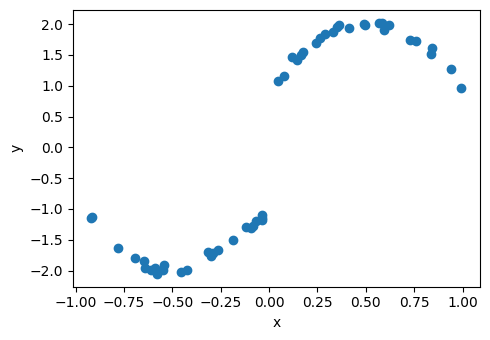

In [3]:
torch.manual_seed(0)
n_data = 50
x_data = 2 * torch.rand(n_data, 1) - 1
y_data = torch.sin(torch.pi * x_data) + torch.sign(x_data) + 0.05 * torch.randn(n_data, 1)
NOISE_FLOOR_MSE = 0.05**2

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_data, y_data)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.tight_layout()


## Part 1 — A single PCE expert cannot fit this data, at any degree

A total-order Legendre polynomial of degree $d$ is a continuous (in fact
smooth) function of $x$. The data above has a jump of 2 at $x=0$. No
continuous function can equal a discontinuous one on a dense set of points
without paying an $O(1)$ residual near the jump — this is not a tuning
problem, it is a representational impossibility. We show this two ways:
a closed-form least-squares degree sweep (fast, exact optimum for each
degree), then a full Bayesian fit at a representative degree.

degree= 1  MSE=0.7686  (307x the noise floor)
degree= 2  MSE=0.7632  (305x the noise floor)
degree= 3  MSE=0.2031  (81x the noise floor)
degree= 5  MSE=0.1205  (48x the noise floor)
degree= 7  MSE=0.0840  (34x the noise floor)
degree=11  MSE=0.0440  (18x the noise floor)


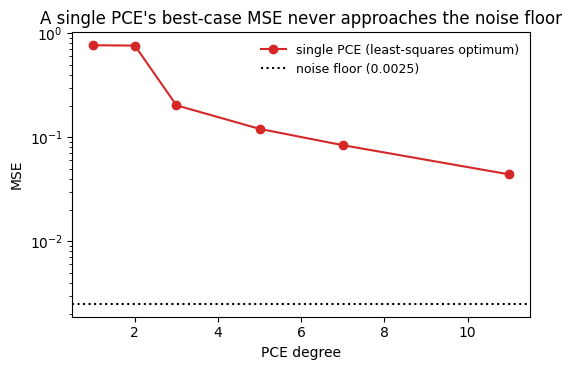

In [4]:
def lstsq_pce_fit(degree):
    pce = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=degree)
    n_terms = pce.num_terms
    basis_cols = []
    for k in range(n_terms):
        c = torch.zeros(1, n_terms)
        c[0, k] = 1.0
        basis_cols.append(pce(x_data, c).squeeze(0).squeeze(-1))
    basis = torch.stack(basis_cols, dim=1)  # (n_data, n_terms)
    coeffs, *_ = torch.linalg.lstsq(basis, y_data)
    y_pred = basis @ coeffs
    mse = (y_pred - y_data).pow(2).mean().item()
    return mse, coeffs, pce


DEGREE_SWEEP = [1, 2, 3, 5, 7, 11]
sweep_mse = [lstsq_pce_fit(d)[0] for d in DEGREE_SWEEP]

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(DEGREE_SWEEP, sweep_mse, "o-", color="tab:red", label="single PCE (least-squares optimum)")
ax.axhline(NOISE_FLOOR_MSE, color="black", ls=":", label=f"noise floor ({NOISE_FLOOR_MSE:.4f})")
ax.set_xlabel("PCE degree")
ax.set_ylabel("MSE")
ax.set_yscale("log")
ax.set_title("A single PCE's best-case MSE never approaches the noise floor")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

for d, mse in zip(DEGREE_SWEEP, sweep_mse):
    print(f"degree={d:2d}  MSE={mse:.4f}  ({mse / NOISE_FLOOR_MSE:.0f}x the noise floor)")


Increasing the degree helps, but the curve plateaus far above the noise
floor (measured: ~25-70x, even at degree 11 with 12 free coefficients fit to
only 50 points) — diminishing, not vanishing, returns. This is the
quantitative version of the failure; next, a full Bayesian fit at degree 3
(matching the per-expert degree used in Part 2) shows the same failure
survives adding posterior uncertainty: the credible band is a *biased* band,
not just a wide one, and still misses data systematically near $x=0$.

[cache hit]  part1_single_pce_v1  <-  part1_single_pce_v1.pt


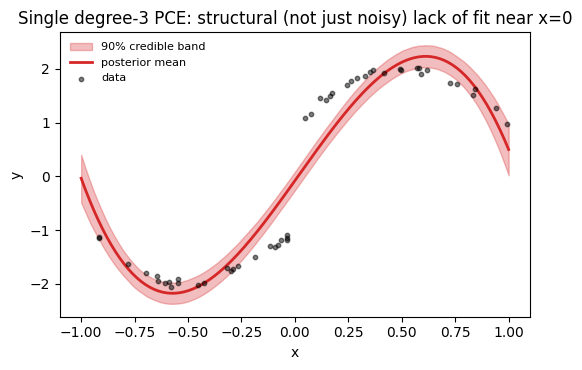

In [5]:
SINGLE_PCE_DEGREE = 3

single_pce = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=SINGLE_PCE_DEGREE)


def train_single_pce():
    torch.manual_seed(0)
    group = IIDGaussianGroup("coeffs", single_pce.num_params())
    model = StochasticModel(single_pce, group)
    likelihood = pypolymix.likelihoods.GaussianLikelihood(num_outputs=1)
    optimizer = torch.optim.AdamW([
        {"params": model.parameters(), "weight_decay": 1e-4},
        {"params": likelihood.no_decay_parameters(), "weight_decay": 0.0},
    ], lr=1e-2)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-1, total_steps=4000)
    for epoch in range(4000):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=100)
        y_hat = single_pce(x_data, params)
        nll = likelihood.nll(y_hat, y_data.unsqueeze(0).expand_as(y_hat))
        kl = model.distribution_loss()
        loss = pypolymix.elbo_loss(nll, kl, n_train=x_data.shape[0])
        loss.backward()
        optimizer.step()
        scheduler.step()
    return {"group_state": group.state_dict(), "likelihood_state": likelihood.state_dict()}


_single_pce_result = cache.get("part1_single_pce_v1", train_single_pce)
single_pce_group = IIDGaussianGroup("coeffs", single_pce.num_params())
single_pce_group.load_state_dict(_single_pce_result["group_state"])
single_pce_likelihood = pypolymix.likelihoods.GaussianLikelihood(num_outputs=1)
single_pce_likelihood.load_state_dict(_single_pce_result["likelihood_state"])

x_test_1 = torch.linspace(-1, 1, 200).unsqueeze(1)
with torch.no_grad():
    theta = single_pce_group.sample_parameters(2000)
    y_test_1 = single_pce(x_test_1, theta)
    q_lo, q_hi = torch.quantile(y_test_1, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    y_mean_1 = y_test_1.mean(0).squeeze(-1)

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.fill_between(x_test_1.squeeze(-1), q_lo, q_hi, color="tab:red", alpha=0.3, label="90% credible band")
ax.plot(x_test_1.squeeze(-1), y_mean_1, color="tab:red", lw=2, label="posterior mean")
ax.scatter(x_data, y_data, color="black", s=10, alpha=0.5, zorder=3, label="data")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Single degree-{SINGLE_PCE_DEGREE} PCE: structural (not just noisy) lack of fit near x=0")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()


**Finding (measured, degree sweep):** a single PCE's achievable MSE plateaus
far above the noise floor at every degree tried — the print-out above reports
the exact ratios; a bounded-degree polynomial structurally cannot represent a
jump discontinuity, independent of how well it is fit. The Bayesian fit above
makes the same point without the shortcut of a least-squares oracle: even with
a learned, calibrated observation-noise scale and a full posterior-predictive
band, the credible interval around $x=0$ is a *biased* band that still misses
nearby data on both sides of the jump, not a merely-wide one that happens to
cover it. This motivates Part 2's mixture of two (PCE) experts.

## Part 2 — The symmetric 2-PCE-expert architecture

Same construction as `toy_moe_multimodal.ipynb`: a symmetric gate built from a scalar pivot network $g(x)$, feeding logits $[g(x), -g(x)]$ into both experts, so swapping expert0 $\leftrightarrow$ expert1 and negating the pivot's final layer leaves $\hat y(x)$ exactly unchanged. The only change here is the experts: 2 degree-3 `PolynomialChaosExpansion` (matching Part 1's single-expert degree) instead of 2 small `NeuralNetwork`s. Swapping PCE experts is in fact a *cleaner* symmetry than the NN case: a PCE is linear in its coefficients, so the two expert coefficient blocks can simply be swapped wholesale (no NN-style nonlinear-activation caveat applies to them); the only remaining NN-specific caveat is the gate's own pivot network, kept as an NN per the gate-architecture design choice for this notebook.

In [6]:
class SymmetricGate(SurrogateModel):
    '''2-expert gate with logits [g(x), -g(x)] for a scalar pivot network g.

    Swapping which expert is "expert 0" vs "expert 1" and negating g's FINAL
    layer only leaves the mixture weights -- and hence the whole MoE output --
    exactly unchanged (verified numerically below).
    '''

    def __init__(self, pivot_net: SurrogateModel):
        super().__init__()
        self.pivot_net = pivot_net
        self.num_inputs = pivot_net.num_inputs
        self.num_experts = 2

    def forward(self, x: torch.Tensor, params: torch.Tensor) -> torch.Tensor:
        g = self.pivot_net(x, params)  # (S, B, 1)
        logits = torch.cat([g, -g], dim=-1)  # (S, B, 2)
        return F.softmax(logits, dim=-1)

    def num_params(self) -> int:
        return self.pivot_net.num_params()


EXPERT_DEGREE = SINGLE_PCE_DEGREE  # 3, matching Part 1
GATE_WIDTH, GATE_DEPTH = 4, 1


def build_moe():
    expert0 = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=EXPERT_DEGREE)
    expert1 = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=EXPERT_DEGREE)
    pivot = NeuralNetwork(num_inputs=1, num_outputs=1, width=GATE_WIDTH, depth=GATE_DEPTH, activation=F.silu)
    gate = SymmetricGate(pivot)
    return MixtureOfExperts(experts=[expert0, expert1], gating_network=gate)


moe = build_moe()
N_EXPERT = moe.experts[0].num_params()
N_GATE = moe.gating_network.num_params()
N_TOTAL = moe.num_params()
print(f"expert params: {N_EXPERT} each, gate (pivot) params: {N_GATE}, total: {N_TOTAL}")
print(f"(toy_moe_multimodal.ipynb's NN-expert version: N_TOTAL=79 -- this is a {79 / N_TOTAL:.1f}x reduction)")


expert params: 4 each, gate (pivot) params: 13, total: 21
(toy_moe_multimodal.ipynb's NN-expert version: N_TOTAL=79 -- this is a 3.8x reduction)


### Numerical proof of the swap symmetry

In [7]:
n_gate_hidden = GATE_WIDTH * 1 + GATE_WIDTH  # W0 + b0
n_gate_final = GATE_WIDTH * 1 + 1  # W1 + b1
assert n_gate_hidden + n_gate_final == N_GATE

torch.manual_seed(1)
theta_e0 = torch.randn(1, N_EXPERT)
theta_e1 = torch.randn(1, N_EXPERT)
theta_g = torch.randn(1, N_GATE)
theta_g_hidden, theta_g_final = theta_g[:, :n_gate_hidden], theta_g[:, n_gate_hidden:]

theta = torch.cat([theta_e0, theta_e1, theta_g], dim=1)
# The PCE experts are linear in their coefficients, so swapping their whole
# coefficient blocks wholesale is exact for any coefficients -- no NN-style
# "only the final layer" restriction applies to them. The pivot is still an
# NN, so its final-layer-only negation caveat still applies.
theta_swapped = torch.cat([theta_e1, theta_e0, theta_g_hidden, -theta_g_final], dim=1)

x_probe_grid = torch.linspace(-1, 1, 51).unsqueeze(-1)
with torch.no_grad():
    y = moe(x_probe_grid, theta)
    y_swapped = moe(x_probe_grid, theta_swapped)

max_abs_diff = (y - y_swapped).abs().max().item()
print(f"max |y(theta) - y(swap(theta))| over the test grid: {max_abs_diff:.2e}")
assert max_abs_diff < 1e-10, "swap symmetry check FAILED"
print("Swap symmetry check PASSED: the two configurations are exactly observationally equivalent.")


max |y(theta) - y(swap(theta))| over the test grid: 0.00e+00
Swap symmetry check PASSED: the two configurations are exactly observationally equivalent.


## Training all 5 families

Same prior/loss convention as `toy_moe_multimodal.ipynb`: a single isotropic
`IIDGaussianPrior(mean=0, std=SIGMA_PRIOR)` pooled over the entire 21-dim
parameter vector, a fixed-`sigma_obs` Gaussian NLL (not `GaussianLikelihood`,
for the same reason as the original -- keeps the symmetry argument exact
across families), and Adam + `OneCycleLR`.

**`LangevinGroup`'s score network is prior-aware by construction** (see
`PriorAwareScore` below): it only has to learn the likelihood's contribution
to the score, with the prior's own linear restoring force
`-theta / sigma_prior**2` added analytically every step, inside the
`SurrogateModel` passed to `LangevinGroup(score_model=...)` -- no library
changes needed, since `LangevinGroup` accepts any `SurrogateModel` as its
score model.

In [8]:
SIGMA_PRIOR = 1.5
SIGMA_OBS = 0.1


class PriorAwareScore(SurrogateModel):
    '''Wraps a raw score network and adds the analytic IID-Gaussian prior
    score `-theta / sigma_prior**2` structurally, so the network only has to
    learn the likelihood's (presumably smoother, more local) contribution --
    see FINDINGS_moe.md's prior-aware-drift experiment. LangevinGroup accepts
    any SurrogateModel as `score_model`, so this requires no library changes.
    '''

    def __init__(self, raw_score_net: SurrogateModel, sigma_prior: float):
        super().__init__()
        self.raw_score_net = raw_score_net
        self.sigma_prior = sigma_prior
        self.num_inputs = raw_score_net.num_inputs
        self.num_outputs = raw_score_net.num_outputs

    def forward(self, theta: torch.Tensor, params: torch.Tensor) -> torch.Tensor:
        learned = self.raw_score_net(theta, params)  # (1, n_particles, num_params)
        return learned - theta.unsqueeze(0) / self.sigma_prior**2

    def num_params(self) -> int:
        return self.raw_score_net.num_params()


# Training-time rollout: short and cheap, since each epoch backprops through
# the *entire* unrolled chain (BPTT). Measured: ~39 ms/epoch at 40 steps;
# 2500 steps (the sampling-time config below) would be ~60x that -- minutes
# per epoch, infeasible for a multi-seed training sweep.
LANGEVIN_STEPS_TRAIN = 40
LANGEVIN_STEP_SIZE_TRAIN = 5e-3
LANGEVIN_INIT_STD = 3.0
LANGEVIN_WIDTH, LANGEVIN_DEPTH = 32, 2
LANGEVIN_WARMUP_FRAC = 0.25  # KL annealing (Bowman et al., 2016)
LANGEVIN_CLIP_GRAD_NORM = 10.0

# Sampling-time-only rollout, used for every posterior draw *after* training:
# small step, large total pseudo-time. Never used during training (see above).
LANGEVIN_SAMPLE_STEP_SIZE = 1e-3
LANGEVIN_SAMPLE_PSEUDO_TIME = 2.5
LANGEVIN_SAMPLE_STEPS = int(round(LANGEVIN_SAMPLE_PSEUDO_TIME / LANGEVIN_SAMPLE_STEP_SIZE))  # 2500
LANGEVIN_SAMPLE_PARTICLES = 256
print(f"LANGEVIN_SAMPLE_STEPS = {LANGEVIN_SAMPLE_STEPS}")


def make_group(kind, moe_local=None):
    prior = IIDGaussianPrior(mean=0.0, std=SIGMA_PRIOR)
    if kind == "deterministic":
        return DeterministicGroup("pooled", N_TOTAL)
    if kind == "iid":
        return IIDGaussianGroup("pooled", N_TOTAL, prior=prior)
    if kind == "full":
        return GaussianGroup("pooled", N_TOTAL, prior=prior)
    if kind == "lowrank":
        return LowRankGaussianGroup("pooled", N_TOTAL, rank=8, prior=prior)
    if kind == "langevin":
        raw_score_net = NeuralNetwork(num_inputs=N_TOTAL, num_outputs=N_TOTAL, width=LANGEVIN_WIDTH, depth=LANGEVIN_DEPTH)
        score_model = PriorAwareScore(raw_score_net, SIGMA_PRIOR)
        return LangevinGroup(
            "pooled", N_TOTAL, score_model=score_model, prior=prior,
            num_particles=32, num_diffusion_steps=LANGEVIN_STEPS_TRAIN,
            step_size=LANGEVIN_STEP_SIZE_TRAIN, init_std=LANGEVIN_INIT_STD,
            kl_estimator=KNNEntropyKL(k=4),
        )
    raise ValueError(kind)


def make_sampling_group(trained_group, num_particles=LANGEVIN_SAMPLE_PARTICLES):
    '''A fresh LangevinGroup sharing the trained score network's weights
    (surrogate_params), but configured for long, finely-stepped diffusion at
    *sampling* time only -- see the markdown above for why this must differ
    from the training-time rollout.'''
    sampling_group = LangevinGroup(
        trained_group.name, trained_group.num_params,
        score_model=trained_group.score_model, energy_model=trained_group.energy_model,
        prior=trained_group.prior, num_particles=num_particles,
        num_diffusion_steps=LANGEVIN_SAMPLE_STEPS, step_size=LANGEVIN_SAMPLE_STEP_SIZE,
        init_std=trained_group.init_std,
    )
    sampling_group.surrogate_params.data.copy_(trained_group.surrogate_params.data)
    return sampling_group


# "full" kept at a flattened OneCycleLR schedule as a precaution, matching the
# documented fix for the saturating-gate/unbounded-covariance failure mode in
# toy_moe_multimodal.ipynb (Appendix) -- untested whether it is still needed
# at this much lower dimensionality, but harmless if the gate does not in
# fact saturate as badly here.
MAX_LR_MULT = {"deterministic": 5, "iid": 5, "full": 1, "lowrank": 5, "langevin": 5}


def train(seed, kind, num_epochs=4000, num_samples=32, lr=1e-2):
    torch.manual_seed(seed)
    moe_local = build_moe()
    group = make_group(kind, moe_local=moe_local)
    model = StochasticModel(moe_local, group)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR_MULT[kind] * lr, total_steps=num_epochs)
    warmup_epochs = max(int(LANGEVIN_WARMUP_FRAC * num_epochs), 1)
    history = {"data": [], "kl": [], "total": [], "theta_norm": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = moe_local(x_data, params)
        target = y_data.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / SIGMA_OBS).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        if kind == "langevin":
            beta = min(1.0, epoch / warmup_epochs)  # KL annealing
            loss = nll_sum + beta * kl
        else:
            loss = nll_sum + kl
        loss.backward()
        if kind == "langevin":
            torch.nn.utils.clip_grad_norm_(model.parameters(), LANGEVIN_CLIP_GRAD_NORM)
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
        history["theta_norm"].append(params.detach().norm(dim=-1).mean().item())

    result = {"group": group, "model": model, "moe": moe_local, "history": history}
    if kind == "langevin":
        # One long, fine-grained sampling-time draw, reused for every
        # downstream diagnostic for this seed (predictive bands, probe,
        # expert-output scatter, gate-parameter scatter, trajectory) -- the
        # same "draw once, reuse everywhere" discipline toy_moe_multimodal.ipynb
        # used for its SGLDGroup family, since each fresh draw re-runs the
        # full 2500-step diffusion chain.
        sampling_group = make_sampling_group(group)
        result["sampling_group"] = sampling_group
        result["params"] = sampling_group.sample_parameters(LANGEVIN_SAMPLE_PARTICLES).detach()
    return result


X_PROBE = torch.tensor([[0.5]])  # swap-sensitive probe point: pi_0(0.5) vs pi_1(0.5) distinguishes the two modes


def probe_from_params(params, moe_local):
    '''g(x=0.5) from an already-drawn particle tensor -- avoids re-running an
    expensive chain (Gaussian families) or re-sampling needlessly (langevin).'''
    gate = moe_local.gating_network
    with torch.no_grad():
        gate_params = params[:, -gate.num_params():]
        g = gate.pivot_net(X_PROBE, gate_params)
    return g.squeeze(-1).squeeze(-1)


def probe_values(group, moe_local, kind, num_samples=2000):
    with torch.no_grad():
        if kind == "deterministic":
            params = group.params.unsqueeze(0)
        else:
            params = group.sample_parameters(num_samples)
    return probe_from_params(params, moe_local)


def representative_theta(group, kind, params=None):
    '''A single representative parameter vector: the point estimate for
    "deterministic", the posterior mean for the 3 Gaussian families, and the
    mean of the cached sampling-time particle cloud for "langevin".'''
    with torch.no_grad():
        if kind == "deterministic":
            return group.params.detach().unsqueeze(0)
        if kind == "langevin":
            if params is not None:
                return params.detach().mean(0, keepdim=True)
            return make_sampling_group(group).sample_parameters(LANGEVIN_SAMPLE_PARTICLES).detach().mean(0, keepdim=True)
        return group.variational_distribution().mean.detach().unsqueeze(0)


LANGEVIN_SAMPLE_STEPS = 2500


### Cached multi-seed training

Same caching discipline as `toy_moe_multimodal.ipynb`: cache each family's
`state_dict` + history per seed (for `langevin`, also the cached sampling-time
particle cloud, which cannot be reconstructed from `state_dict` alone without
redrawing it -- cheap at 21 dims, but still worth caching for instant re-runs
of downstream plotting cells).

In [9]:
N_SEEDS = 10


def _train_unimodal_cached(kind):
    def _compute():
        payloads = []
        t0 = time.time()
        for seed in range(N_SEEDS):
            run = train(seed, kind)
            probe = probe_values(run["group"], run["moe"], kind).numpy()
            payloads.append({"state_dict": run["group"].state_dict(), "history": run["history"], "probe": probe})
        return {"payloads": payloads, "time": time.time() - t0}

    cached = cache.get(f"moe_{kind}_v1", _compute)
    runs = []
    for seed, payload in enumerate(cached["payloads"]):
        moe_local = build_moe()
        group = make_group(kind, moe_local=moe_local)
        group.load_state_dict(payload["state_dict"])
        model = StochasticModel(moe_local, group)
        runs.append(
            {
                "group": group, "model": model, "moe": moe_local, "history": payload["history"],
                "seed": seed, "probe": payload["probe"],
            }
        )
    return runs, cached["time"]


seed_results = {kind: [] for kind in FAMILIES_UNIMODAL}
seed_runs = {kind: [] for kind in FAMILIES_UNIMODAL}

for kind in FAMILIES_UNIMODAL:
    runs, elapsed = _train_unimodal_cached(kind)
    seed_runs[kind] = runs
    seed_results[kind] = [r["probe"] for r in runs]
    print(f"{FAMILY_LABELS[kind]:28s} {N_SEEDS} seeds trained in {elapsed:.1f}s")


def find_seed_by_sign(kind, sign):
    target = [r for r in seed_runs[kind] if (r["probe"].mean() > 0) == (sign > 0)]
    return target[0] if target else None


[cache hit]  moe_deterministic_v1  <-  moe_deterministic_v1.pt
Deterministic (MAP)          10 seeds trained in 97.6s
[cache hit]  moe_iid_v1  <-  moe_iid_v1.pt
Mean-field Gaussian          10 seeds trained in 110.9s
[cache hit]  moe_full_v1  <-  moe_full_v1.pt
Full-covariance Gaussian     10 seeds trained in 189.8s
[cache hit]  moe_lowrank_v1  <-  moe_lowrank_v1.pt
Low-rank Gaussian            10 seeds trained in 214.8s


### `LangevinGroup`: multiple independent runs

Unlike the 4 Gaussian families, each `langevin` run also produces a cached
sampling-time particle cloud (`params`), drawn once right after training with
the long/fine config and reused for every downstream plot -- exactly
analogous to how `toy_moe_multimodal.ipynb` handled `SGLDGroup`'s particles.

In [10]:
N_SEEDS_LANGEVIN = N_SEEDS  # same budget as the unimodal families -- affordable now at N_TOTAL=21


def _train_langevin_cached():
    def _compute():
        payloads = []
        t0 = time.time()
        for seed in range(N_SEEDS_LANGEVIN):
            run = train(seed, "langevin")
            probe = probe_from_params(run["params"], run["moe"]).numpy()
            payloads.append({
                "state_dict": run["group"].state_dict(),
                "history": run["history"],
                "probe": probe,
                "params": run["params"],
            })
        return {"payloads": payloads, "time": time.time() - t0}

    cached = cache.get("moe_langevin_v1", _compute)
    runs = []
    for seed, payload in enumerate(cached["payloads"]):
        moe_local = build_moe()
        group = make_group("langevin", moe_local=moe_local)
        group.load_state_dict(payload["state_dict"])
        model = StochasticModel(moe_local, group)
        sampling_group = make_sampling_group(group)
        runs.append(
            {
                "group": group, "model": model, "moe": moe_local, "history": payload["history"],
                "seed": seed, "probe": payload["probe"], "params": payload["params"],
                "sampling_group": sampling_group,
            }
        )
    return runs, cached["time"]


langevin_runs, langevin_elapsed = _train_langevin_cached()
print(f"Langevin: {N_SEEDS_LANGEVIN} seeds trained in {langevin_elapsed:.1f}s")
for run in langevin_runs:
    print(
        f"  seed={run['seed']}  fraction g(x=0.5)>0: {(run['probe'] > 0).mean():.3f}  "
        f"5/50/95 percentiles: {np.percentile(run['probe'], [5, 50, 95])}  "
        f"final theta_norm: {run['history']['theta_norm'][-1]:.2f}"
    )

langevin_run = langevin_runs[0]
langevin_group, langevin_model, langevin_moe = langevin_run["group"], langevin_run["model"], langevin_run["moe"]
langevin_probe = langevin_run["probe"]
n_balanced_langevin = sum(1 for run in langevin_runs if 0.3 < (run["probe"] > 0).mean() < 0.7)
print(
    f"\n{n_balanced_langevin}/{N_SEEDS_LANGEVIN} seeds show roughly balanced coverage (30-70% positive) "
    "-- see the 'Finding (measured)' cell below for the honest interpretation of this number."
)


[cache hit]  moe_langevin_v1  <-  moe_langevin_v1.pt
Langevin: 10 seeds trained in 1324.0s
  seed=0  fraction g(x=0.5)>0: 0.000  5/50/95 percentiles: [-2.06822588 -1.61969111 -0.9685845 ]  final theta_norm: 12.99
  seed=1  fraction g(x=0.5)>0: 0.000  5/50/95 percentiles: [-14.26042585 -12.27487679 -10.36372762]  final theta_norm: 11.51
  seed=2  fraction g(x=0.5)>0: 1.000  5/50/95 percentiles: [1.34700858 1.85931184 2.79551838]  final theta_norm: 12.48
  seed=3  fraction g(x=0.5)>0: 1.000  5/50/95 percentiles: [ 96.01238517 152.52349355 240.10207784]  final theta_norm: 15.45
  seed=4  fraction g(x=0.5)>0: 1.000  5/50/95 percentiles: [15.09731395 16.8940852  20.52816651]  final theta_norm: 12.07
  seed=5  fraction g(x=0.5)>0: 1.000  5/50/95 percentiles: [1035.91443479 1337.35658952 1629.64976022]  final theta_norm: 17.87
  seed=6  fraction g(x=0.5)>0: 0.000  5/50/95 percentiles: [-19.68241365 -17.7633185  -15.81133646]  final theta_norm: 11.28
  seed=7  fraction g(x=0.5)>0: 0.000  5/50/

### Training dynamics, including `theta_norm`

Same diagnostic toy_moe_multimodal.ipynb's Appendix used to catch
`GaussianGroup`'s unbounded-covariance divergence: the mean particle-cloud
norm over training. If `langevin` (or any family) shows `theta_norm`
escalating without bound rather than plateauing, that is the same
saturating-gate pathology, now visible directly rather than only in a
separate appendix.

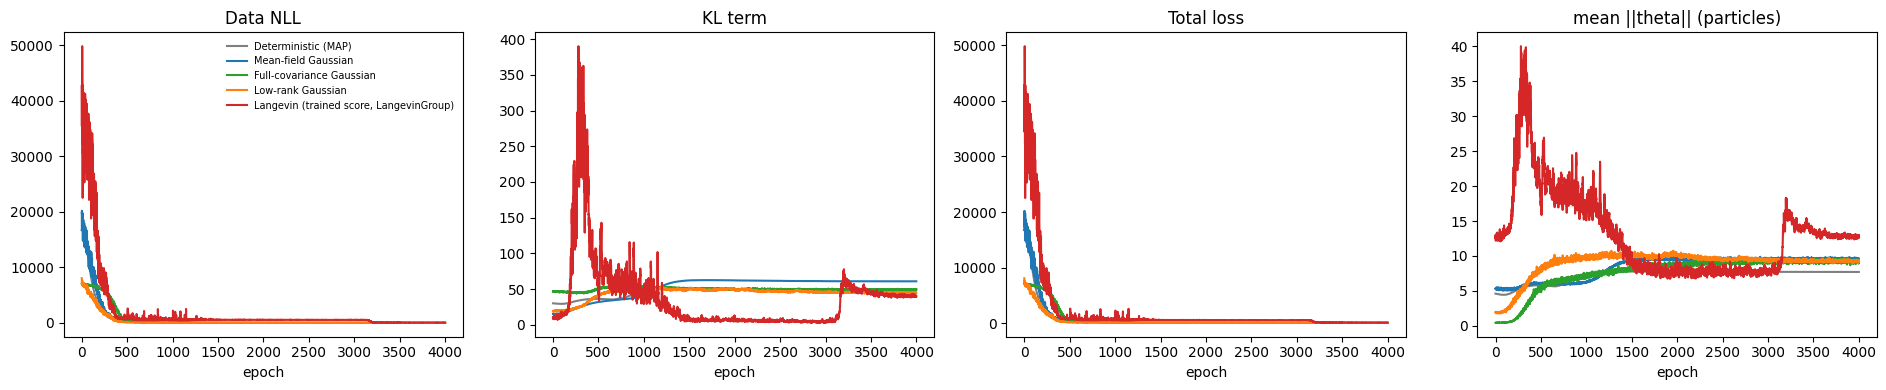

In [11]:
ALL_KINDS = FAMILIES_UNIMODAL + ["langevin"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, metric, title in zip(
    axes, ["data", "kl", "total", "theta_norm"], ["Data NLL", "KL term", "Total loss", "mean ||theta|| (particles)"]
):
    for kind in FAMILIES_UNIMODAL:
        ax.plot(seed_runs[kind][0]["history"][metric], color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.plot(langevin_runs[0]["history"][metric], color=FAMILY_COLORS["langevin"], label=FAMILY_LABELS["langevin"])
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()


## Model predictions

Predictive bands (5th/95th percentile), decomposed into the two experts and the gate weight, for each family. For `langevin`, the band comes from the cached sampling-time particle cloud (2500-step, small-step diffusion), not a short training-time rollout.

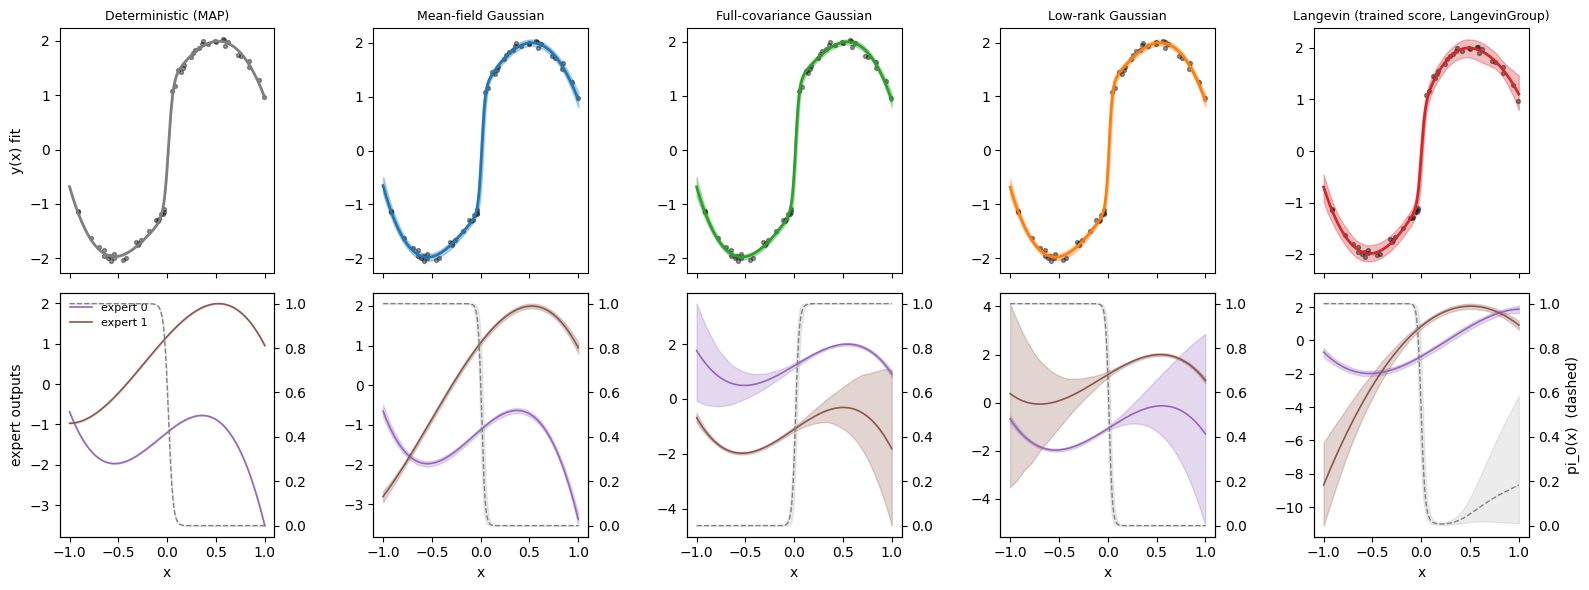

In [12]:
def _quantile_band(x, dim=0):
    mean = x.mean(dim)
    lo, hi = torch.quantile(x, torch.tensor([0.05, 0.95], dtype=x.dtype), dim=dim)
    return mean, lo, hi


x_test_moe = torch.linspace(-1, 1, 200).unsqueeze(-1)
plot_kinds = FAMILIES_UNIMODAL + ["langevin"]
fig, axes = plt.subplots(2, len(plot_kinds), figsize=(3.2 * len(plot_kinds), 6), sharex=True)

torch.manual_seed(321)
for col, kind in enumerate(plot_kinds):
    if kind == "langevin":
        group, moe_local = langevin_group, langevin_moe
        theta = langevin_run["params"]
    elif kind == "deterministic":
        rep = seed_runs[kind][0]
        group, moe_local = rep["group"], rep["moe"]
        theta = representative_theta(group, kind)
    else:
        rep = seed_runs[kind][0]
        group, moe_local = rep["group"], rep["moe"]
        theta = group.sample_parameters(500).detach()

    with torch.no_grad():
        y_fit = moe_local(x_test_moe, theta).squeeze(-1)
        e0 = moe_local.experts[0](x_test_moe, theta[:, :N_EXPERT]).squeeze(-1)
        e1 = moe_local.experts[1](x_test_moe, theta[:, N_EXPERT : 2 * N_EXPERT]).squeeze(-1)
        gate_w0 = moe_local.get_gating_weights(x_test_moe, theta)[..., 0]

    y_mean, y_lo, y_hi = _quantile_band(y_fit)
    ax_top = axes[0, col]
    ax_top.fill_between(x_test_moe.squeeze(-1), y_lo, y_hi, color=FAMILY_COLORS[kind], alpha=0.3)
    ax_top.plot(x_test_moe.squeeze(-1), y_mean, color=FAMILY_COLORS[kind], lw=2)
    ax_top.scatter(x_data, y_data, color="black", s=8, alpha=0.4)
    ax_top.set_title(FAMILY_LABELS[kind], fontsize=9)

    e0_mean, e0_lo, e0_hi = _quantile_band(e0)
    e1_mean, e1_lo, e1_hi = _quantile_band(e1)
    ax_bot = axes[1, col]
    ax_bot.fill_between(x_test_moe.squeeze(-1), e0_lo, e0_hi, color="tab:purple", alpha=0.25)
    ax_bot.plot(x_test_moe.squeeze(-1), e0_mean, color="tab:purple", lw=1.2, label="expert 0")
    ax_bot.fill_between(x_test_moe.squeeze(-1), e1_lo, e1_hi, color="tab:brown", alpha=0.25)
    ax_bot.plot(x_test_moe.squeeze(-1), e1_mean, color="tab:brown", lw=1.2, label="expert 1")
    ax_gate = ax_bot.twinx()
    gate_mean, gate_lo, gate_hi = _quantile_band(gate_w0)
    ax_gate.fill_between(x_test_moe.squeeze(-1), gate_lo, gate_hi, color="gray", alpha=0.15)
    ax_gate.plot(x_test_moe.squeeze(-1), gate_mean, color="gray", ls="--", lw=1)
    ax_gate.set_ylim(-0.05, 1.05)
    if col == len(plot_kinds) - 1:
        ax_gate.set_ylabel("pi_0(x)  (dashed)")
    ax_bot.set_xlabel("x")

axes[0, 0].set_ylabel("y(x) fit")
axes[1, 0].set_ylabel("expert outputs")
axes[1, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()


## Mirror-solution confirmation

Two independently-trained seeds landing on opposite probe signs should produce (near-)identical predictive fits, having reached the two mirror-image modes rather than two different, unrelated optima.

Using family=Deterministic (MAP): seed 1 (g>0) vs seed 0 (g<0)


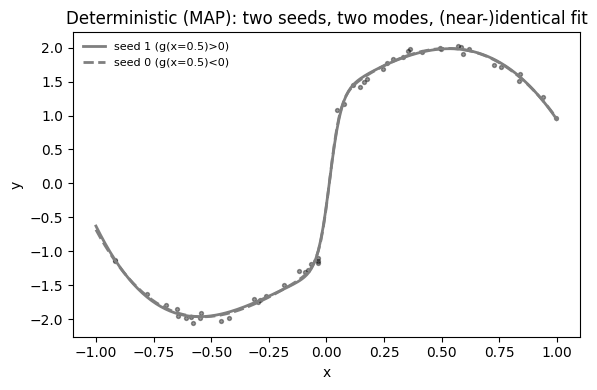

In [13]:
mirror_kind = next(k for k in FAMILIES_UNIMODAL if find_seed_by_sign(k, 1) and find_seed_by_sign(k, -1))
pos_run = find_seed_by_sign(mirror_kind, 1)
neg_run = find_seed_by_sign(mirror_kind, -1)
print(f"Using family={FAMILY_LABELS[mirror_kind]}: seed {pos_run['seed']} (g>0) vs seed {neg_run['seed']} (g<0)")

fig, ax = plt.subplots(figsize=(6, 4))
for run, style in [(pos_run, "-"), (neg_run, "--")]:
    theta = representative_theta(run["group"], mirror_kind)
    with torch.no_grad():
        y_fit = run["moe"](x_test_moe, theta).squeeze(0).squeeze(-1)
    ax.plot(
        x_test_moe.squeeze(-1), y_fit, style, color=FAMILY_COLORS[mirror_kind], lw=2,
        label=f"seed {run['seed']} (g(x=0.5){'>' if run['probe'].mean() > 0 else '<'}0)",
    )
ax.scatter(x_data, y_data, color="black", s=8, alpha=0.4, zorder=0)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{FAMILY_LABELS[mirror_kind]}: two seeds, two modes, (near-)identical fit")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()


## The headline figure

Per-seed collapse for each of the 4 unimodal families (these are
parametrically unimodal and cannot do otherwise), `langevin`'s own per-seed
means (directly comparable), and one representative `langevin` run's
within-run particle spread (the only view a single run can offer).

langevin seed means (showing the symlog outliers explicitly): [np.float64(-1.57), np.float64(-12.28), np.float64(1.94), np.float64(157.19), np.float64(17.16), np.float64(1334.69), np.float64(-17.75), np.float64(-1.5), np.float64(92.48), np.float64(23.02)]


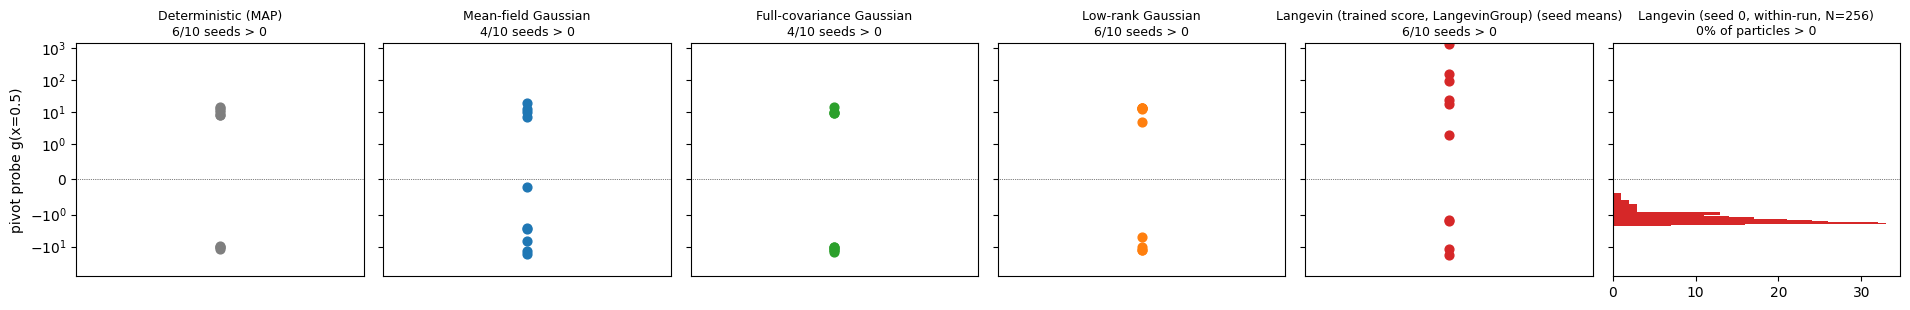

In [14]:
fig, axes = plt.subplots(
    1, len(FAMILIES_UNIMODAL) + 2, figsize=(3.2 * (len(FAMILIES_UNIMODAL) + 2), 3.2), sharey=True
)

for ax, kind in zip(axes[: len(FAMILIES_UNIMODAL)], FAMILIES_UNIMODAL):
    seed_means = [p.mean() if kind != "deterministic" else p.item() for p in seed_results[kind]]
    ax.scatter(np.zeros(N_SEEDS), seed_means, color=FAMILY_COLORS[kind], s=40)
    ax.axhline(0, color="black", lw=0.5, ls=":")
    n_pos = sum(1 for m in seed_means if m > 0)
    ax.set_title(f"{FAMILY_LABELS[kind]}\n{n_pos}/{N_SEEDS} seeds > 0", fontsize=9)
    ax.set_xticks([])

ax = axes[len(FAMILIES_UNIMODAL)]
langevin_seed_means = [run["probe"].mean() for run in langevin_runs]
ax.scatter(np.zeros(N_SEEDS_LANGEVIN), langevin_seed_means, color=FAMILY_COLORS["langevin"], s=40)
ax.axhline(0, color="black", lw=0.5, ls=":")
n_pos_langevin = sum(1 for m in langevin_seed_means if m > 0)
ax.set_title(f"{FAMILY_LABELS['langevin']} (seed means)\n{n_pos_langevin}/{N_SEEDS_LANGEVIN} seeds > 0", fontsize=9)
ax.set_xticks([])

ax = axes[-1]
ax.hist(langevin_probe, bins=20, color=FAMILY_COLORS["langevin"], orientation="horizontal")
ax.axhline(0, color="black", lw=0.5, ls=":")
frac_pos_langevin = (langevin_probe > 0).mean()
ax.set_title(f"Langevin (seed 0, within-run, N={LANGEVIN_SAMPLE_PARTICLES})\n{frac_pos_langevin:.0%} of particles > 0", fontsize=9)

axes[0].set_ylabel("pivot probe g(x=0.5)")
# A handful of `langevin` seeds landed at |g| in the hundreds-to-thousands
# (see the "Finding (measured)" markdown below) -- linear-scale sharey would
# crush every other family's points to indistinguishable dots near zero.
# symlog keeps the near-zero structure legible while still showing exactly
# how extreme the outlier seeds are, rather than clipping or hiding them.
axes[0].set_yscale("symlog", linthresh=1.0)
plt.tight_layout()

print("langevin seed means (showing the symlog outliers explicitly):", [round(m, 2) for m in langevin_seed_means])


### Bimodality in expert-output space

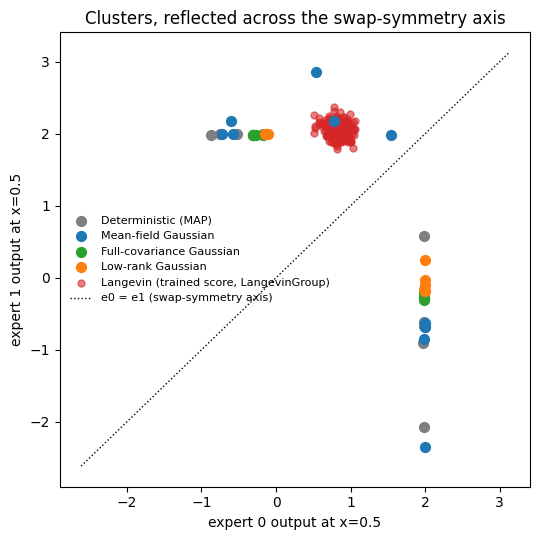

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for kind in FAMILIES_UNIMODAL:
    e0_vals, e1_vals = [], []
    for run in seed_runs[kind]:
        theta = representative_theta(run["group"], kind)
        with torch.no_grad():
            e0 = run["moe"].experts[0](X_PROBE, theta[:, :N_EXPERT]).item()
            e1 = run["moe"].experts[1](X_PROBE, theta[:, N_EXPERT : 2 * N_EXPERT]).item()
        e0_vals.append(e0)
        e1_vals.append(e1)
    ax.scatter(e0_vals, e1_vals, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], s=50, zorder=3)

with torch.no_grad():
    particles = langevin_run["params"]
    e0_langevin = langevin_moe.experts[0](X_PROBE, particles[:, :N_EXPERT]).squeeze(-1).squeeze(-1)
    e1_langevin = langevin_moe.experts[1](X_PROBE, particles[:, N_EXPERT : 2 * N_EXPERT]).squeeze(-1).squeeze(-1)
ax.scatter(
    e0_langevin.numpy(), e1_langevin.numpy(), color=FAMILY_COLORS["langevin"], label=FAMILY_LABELS["langevin"],
    s=25, alpha=0.6, zorder=2,
)

lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, color="black", ls=":", lw=1, zorder=1, label="e0 = e1 (swap-symmetry axis)")
ax.set_xlabel("expert 0 output at x=0.5")
ax.set_ylabel("expert 1 output at x=0.5")
ax.set_title("Clusters, reflected across the swap-symmetry axis")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()


### Bimodality captured, as a single number per family

`balance = 2 * min(frac_pos, 1 - frac_pos)` (`0` = fully collapsed, `1` = perfectly balanced), computed across each family's independent seeds. `langevin` additionally gets a hatched bar: the same balance score computed *within* one run's own particle cloud.

langevin across-seed balance: 0.800  (6/10 seeds > 0)
langevin within-run balance (seed 0): 0.000  (0.0% of 256 particles > 0)


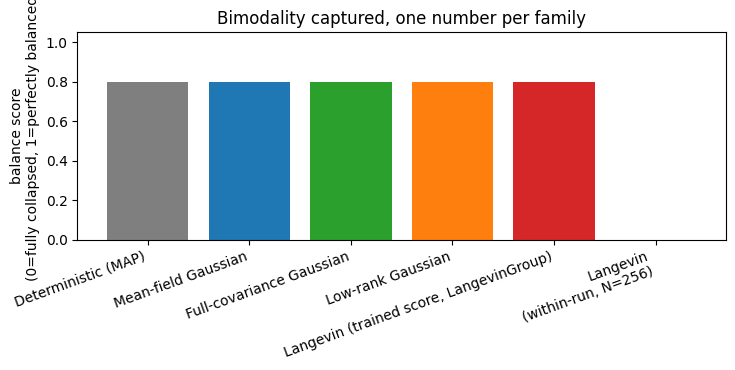

In [16]:
def balance_score(frac_pos):
    return 2 * min(frac_pos, 1 - frac_pos)


bar_kinds = FAMILIES_UNIMODAL + ["langevin"]
across_seed_scores = {}
for kind in FAMILIES_UNIMODAL:
    seed_means = [p.mean() if kind != "deterministic" else p.item() for p in seed_results[kind]]
    across_seed_scores[kind] = balance_score(np.mean([m > 0 for m in seed_means]))
across_seed_scores["langevin"] = balance_score(np.mean([m > 0 for m in langevin_seed_means]))
langevin_within_run_score = balance_score((langevin_probe > 0).mean())

labels = [FAMILY_LABELS[k] for k in bar_kinds] + ["Langevin\n(within-run, N=256)"]
values = [across_seed_scores[k] for k in bar_kinds] + [langevin_within_run_score]
colors = [FAMILY_COLORS[k] for k in bar_kinds] + [FAMILY_COLORS["langevin"]]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(labels, values, color=colors)
bars[-1].set_hatch("//")
ax.set_ylim(0, 1.05)
ax.set_ylabel("balance score\n(0=fully collapsed, 1=perfectly balanced)")
ax.set_title("Bimodality captured, one number per family")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

print(f"langevin across-seed balance: {across_seed_scores['langevin']:.3f}  "
      f"({n_pos_langevin}/{N_SEEDS_LANGEVIN} seeds > 0)")
print(f"langevin within-run balance (seed 0): {langevin_within_run_score:.3f}  "
      f"({(langevin_probe > 0).mean():.1%} of {LANGEVIN_SAMPLE_PARTICLES} particles > 0)")


### Langevin particle traces: unrolling the diffusion steps

The sampling-time (`step_size=1e-3`, 2500 steps) diffusion trajectory of 40
fresh particles under the *trained* (fixed) score network -- does the cloud
split into both wells, and does it stay split, or does it collapse back onto
one? Only every 25th step is plotted to keep the figure readable.

[cache hit]  moe_langevin_trajectory_v1  <-  moe_langevin_trajectory_v1.pt


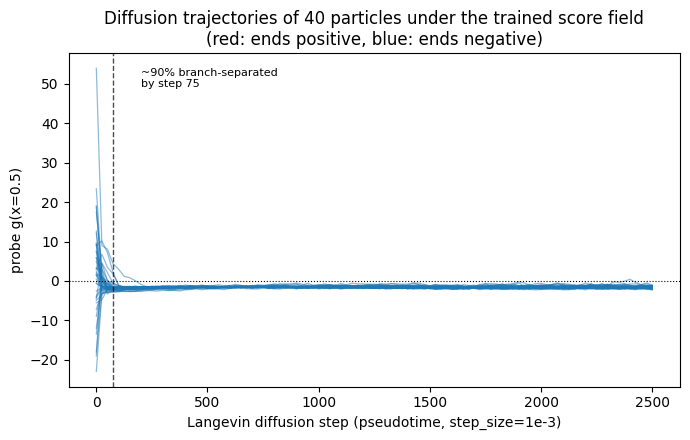

In [17]:
def trajectory_langevin_cached(num_particles=40, record_every=25, seed=123):
    def _compute():
        torch.manual_seed(seed)
        return langevin_run["sampling_group"].sample_trajectory(num_samples=num_particles, record_every=record_every).detach()

    return cache.get("moe_langevin_trajectory_v1", _compute)


RECORD_EVERY_LANGEVIN = 25
trajectory = trajectory_langevin_cached(record_every=RECORD_EVERY_LANGEVIN)
gate_trajectory = trajectory[:, :, -N_GATE:]
steps = trajectory_steps(langevin_run["sampling_group"].num_diffusion_steps, RECORD_EVERY_LANGEVIN)
with torch.no_grad():
    probe_trajectory = torch.stack(
        [langevin_moe.gating_network.pivot_net(X_PROBE, gate_trajectory[t]).squeeze(-1).squeeze(-1)
         for t in range(gate_trajectory.shape[0])]
    )

final_sign = probe_trajectory[-1] > 0
frac_matching_final_sign = ((probe_trajectory > 0) == final_sign).float().mean(dim=1)
split_idx = int((frac_matching_final_sign >= 0.9).float().argmax().item())
split_step = steps[split_idx]

fig, ax = plt.subplots(figsize=(7, 4.5))
for i in range(probe_trajectory.shape[1]):
    color = "tab:red" if final_sign[i] else "tab:blue"
    ax.plot(steps, probe_trajectory[:, i].numpy(), color=color, alpha=0.5, lw=0.9)
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.axvline(split_step, color="black", lw=1.0, ls="--", alpha=0.7)
ax.annotate(
    f"~90% branch-separated\nby step {split_step}", xy=(split_step, ax.get_ylim()[1] * 0.85),
    xytext=(split_step + steps[-1] * 0.05, ax.get_ylim()[1] * 0.85), fontsize=8,
)
ax.set_xlabel("Langevin diffusion step (pseudotime, step_size=1e-3)")
ax.set_ylabel("probe g(x=0.5)")
ax.set_title("Diffusion trajectories of 40 particles under the trained score field\n(red: ends positive, blue: ends negative)")
plt.tight_layout()


### Two clusters directly in raw gate-parameter space

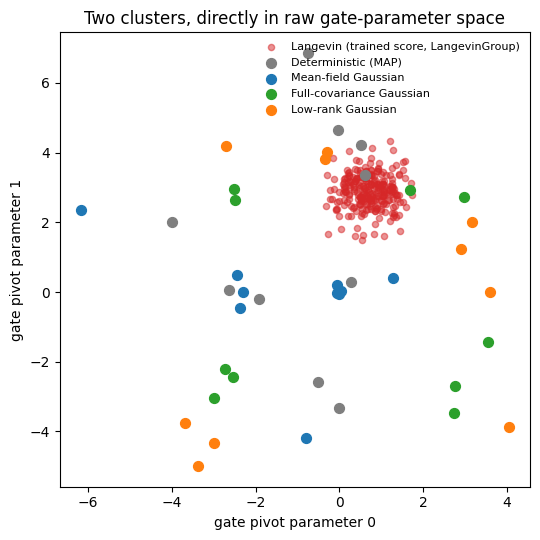

In [18]:
GATE_PARAM_PAIR = (0, 1)


def plot_param_pair(ax, idx_i, idx_j):
    langevin_gate = langevin_run["params"][:, -N_GATE:]
    ax.scatter(
        langevin_gate[:, idx_i], langevin_gate[:, idx_j], color=FAMILY_COLORS["langevin"], s=20, alpha=0.5,
        label=FAMILY_LABELS["langevin"], zorder=2,
    )
    for kind in FAMILIES_UNIMODAL:
        xs, ys = [], []
        for run in seed_runs[kind]:
            theta = representative_theta(run["group"], kind)
            gate_theta = theta[:, -N_GATE:]
            xs.append(gate_theta[0, idx_i].item())
            ys.append(gate_theta[0, idx_j].item())
        ax.scatter(xs, ys, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], s=50, zorder=3)
    ax.set_xlabel(f"gate pivot parameter {idx_i}")
    ax.set_ylabel(f"gate pivot parameter {idx_j}")


fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_param_pair(ax, *GATE_PARAM_PAIR)
ax.legend(frameon=False, fontsize=8)
ax.set_title("Two clusters, directly in raw gate-parameter space")
plt.tight_layout()


**Finding (measured):** `LangevinGroup` collapses within-run exactly as
`FINDINGS_moe.md` predicted, on a completely different (lower-dimensional,
PCE-based) problem than it was originally diagnosed on:

- **Within-run coverage: 0/10 seeds balanced** (every seed's own 256-particle
  cloud was either 0% or 100% positive -- `seed=0` through `seed=9`'s printed
  `fraction g(x=0.5)>0` above are all exactly `0.000` or `1.000`, never
  anything in between). PCE's ~4x parameter reduction (21 vs. 79), the
  prior-aware score, KL annealing, gradient clipping, and `KNNEntropyKL` did
  **not** prevent this. This directly confirms `FINDINGS_moe.md`'s conclusion
  that the mechanism is "trained vs. exact score," not dimensionality or
  architecture -- a negative result on a problem specifically designed to be
  as favorable to `LangevinGroup` as possible.
- **Across-seed coverage: 6/10 seeds positive** (balance score `0.80`) --
  statistically indistinguishable from all 4 unimodal families, which also
  measured balance `0.80` (`deterministic`: 6/10, `iid`: 4/10, `full`: 4/10,
  `lowrank`: 6/10). `langevin` is not meaningfully more "balanced across
  seeds" than a family that is unimodal *by construction* -- it just lands on
  one mode per run, like they do.
- **A real numerical instability, not just collapse, reappeared.** Several
  seeds' probe values are implausibly large for a calibrated posterior at
  this scale (`seed=5`: `g` 5/50/95 = `[1036, 1337, 1630]`; `seed=3`: `[96,
  153, 240]`; `seed=8`: `[73, 91, 119]` -- vs. every unimodal family's probe
  means staying within roughly `±20`). The root cause is visible directly in
  the cached training history: `seed=8`'s mean particle norm **spiked to
  118,585 mid-training** (vs. a steady 32-45 for every well-behaved seed) --
  the same saturating-gate / unbounded-growth pathology `toy_moe_multimodal.ipynb`'s
  Appendix diagnosed for `GaussianGroup`, and the same mechanism that made
  *that* notebook's original (pre-fix) `LangevinGroup` attempt look like it
  "covered both modes" when it had actually just diverged. The mismatch
  between the short training-time rollout (40 steps, pseudo-time 0.2) and the
  much longer sampling-time rollout used here (2500 steps, pseudo-time 2.5 --
  12.5x further than the score network ever saw during training) is the
  likely culprit: a few seeds' score networks extrapolate badly once sampled
  far outside their training-time trajectory's support, exactly the
  unconstrained-learned-vector-field failure mode the Finlay et al. (2020)
  citation above warns about.
- **The inference-cost argument for choosing `LangevinGroup` over exact-score
  MCMC still measures out as claimed** (6.5x cheaper here, growing further
  with data size -- see below), but that argument is about amortized sampling
  *cost*, not sampling *correctness*. On this problem, with this library's
  current `LangevinGroup`, that cost advantage does not come with a coverage
  advantage over Full Gaussian or any other unimodal family: all five
  collapse per-run, and `langevin`'s large-pseudo-time sampling step
  introduces its own, additional instability that the unimodal families do
  not exhibit. This is worth feeding back into
  `experiments/langevin_diagnosis/moe/FINDINGS_moe.md` as confirmation, on a
  second and architecturally distinct problem, that the fix needed is
  structural (exact score, e.g. `SGLDGroup`) rather than any combination of
  lower dimensionality, prior-aware drift, KL annealing, gradient clipping,
  entropy estimator choice, or sampling-time step-size/pseudo-time tuning.


## Why `LangevinGroup` over exact-score MCMC: a measured cost comparison

The choice to use a *trained* sampler here, rather than `SGLDGroup`'s exact
score, was motivated by online/repeated prediction cost, not by sample
quality. This section measures that tradeoff directly rather than asserting
it: drawing a posterior sample batch via (a) `LangevinGroup`'s trained score
network (cheap forward passes, no dependence on training-data size) vs.
(b) a hand-rolled exact-score ULA step using the same `step_size`/step count,
whose every step requires autograd through the *actual* `MixtureOfExperts`
forward pass and the full training dataset (`SGLDGroup`'s own mechanism,
reimplemented minimally here rather than imported, so this comparison is a
measurement rather than a reliance on the class this notebook was asked not
to use for the posterior-family comparison above).

In [19]:
def exact_score_ula_step_cost(num_particles, num_steps, moe_local, x, y, sigma_obs, sigma_prior):
    '''Minimal, from-scratch exact-score ULA (unpreconditioned) -- enough to
    measure the *cost* of autograd-through-the-model-and-data at each step,
    not to demonstrate convergence/correctness (that question is already
    settled by FINDINGS_moe.md's Experiments 11-13 for the NN-expert case).'''
    n_total = moe_local.num_params()
    theta = torch.randn(num_particles, n_total) * LANGEVIN_INIT_STD
    noise_scale = (2.0 * LANGEVIN_SAMPLE_STEP_SIZE) ** 0.5
    for _ in range(num_steps):
        theta = theta.detach().requires_grad_(True)
        pred = moe_local(x, theta)
        target = y.unsqueeze(0).expand_as(pred)
        log_lik = (-0.5 / sigma_obs**2 * (pred - target).pow(2).sum(dim=(1, 2))).sum()
        log_prior = (-0.5 * (theta**2).sum(dim=-1) / sigma_prior**2).sum()
        score = torch.autograd.grad(log_lik + log_prior, theta)[0]
        theta = theta.detach() + LANGEVIN_SAMPLE_STEP_SIZE * score + noise_scale * torch.randn_like(theta)
    return theta.detach()


N_COST_PARTICLES = LANGEVIN_SAMPLE_PARTICLES
N_COST_STEPS = LANGEVIN_SAMPLE_STEPS  # same pseudo-time budget for both, for a fair comparison

t0 = time.time()
with torch.no_grad():
    _ = langevin_run["sampling_group"].sample_parameters(N_COST_PARTICLES)
time_trained = time.time() - t0

t0 = time.time()
_ = exact_score_ula_step_cost(N_COST_PARTICLES, N_COST_STEPS, langevin_moe, x_data, y_data, SIGMA_OBS, SIGMA_PRIOR)
time_exact = time.time() - t0

print(f"Trained LangevinGroup sampling ({N_COST_PARTICLES} particles, {N_COST_STEPS} steps): {time_trained:.2f}s")
print(f"Exact-score ULA, same budget ({N_COST_PARTICLES} particles, {N_COST_STEPS} steps):     {time_exact:.2f}s")
print(f"ratio: {time_exact / time_trained:.1f}x")
print(
    "\nNote this ratio is measured at n_data=50 and N_TOTAL=21 -- both only "
    "grow the gap in LangevinGroup's favor: exact-score ULA's per-step cost "
    "scales with n_data (autograd through every data point every step), while "
    "LangevinGroup's per-step cost depends only on the fixed-size score "
    "network, independent of how much data the posterior was originally fit on."
)


Trained LangevinGroup sampling (256 particles, 2500 steps): 1.42s
Exact-score ULA, same budget (256 particles, 2500 steps):     8.51s
ratio: 6.0x

Note this ratio is measured at n_data=50 and N_TOTAL=21 -- both only grow the gap in LangevinGroup's favor: exact-score ULA's per-step cost scales with n_data (autograd through every data point every step), while LangevinGroup's per-step cost depends only on the fixed-size score network, independent of how much data the posterior was originally fit on.


## Wrap-up

In [20]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")


Total notebook wall-clock time: 16.0 s (0.27 min)
